# Case 01, part III: reading a staged rollout

Everything here is simulated. The repaired new station is re-released through a staged
rollout, and the baseline yield drifts upwards while the share routed to it rises. This
notebook reads the committed operating-characteristics tables and the committed run, prints
the numbers the rollout README states, and draws figures T1 to T3. It runs no simulation.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from abforensics.reporting import PALETTE, apply_style

apply_style()
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
CASE = ROOT / "case_studies" / "01_lost_logs_found_lift" / "rollout"
RES = ROOT / "results" / "case01" / "rollout"
FIG = CASE / "figures"
FIG.mkdir(exist_ok=True)
config = yaml.safe_load((CASE / "config.yaml").read_text(encoding="utf-8"))

scenarios = pd.read_csv(RES / "oc_rollout_scenarios.csv")
canary = pd.read_csv(RES / "oc_rollout_canary.csv")
s1 = pd.read_csv(RES / "oc_rollout_s1_distribution.csv")
run = pd.read_csv(RES / "run_estimates.csv")
run_canary = pd.read_csv(RES / "run_canary.csv")
meta = json.loads((RES / "oc_rollout_meta.json").read_text(encoding="utf-8"))
COLOURS = [PALETTE["control"], PALETTE["treatment"], PALETTE["series3"]]
pd.set_option("display.width", 160)
print(f"replicates {meta['replicates']}, canary replicates {meta['canary_replicates']}")

replicates 5000, canary replicates 10000


## The schedule

Each product is routed to the new station with the probability of its arrival day's stage.

In [2]:
print(canary[["stage", "first_day", "last_day", "routing_p", "products"]].to_string(index=False))

 stage  first_day  last_day  routing_p  products
     1          1         7       0.01    140000
     2          8        14       0.10    140000
     3         15        28       0.50    280000


## Operating characteristics

Rates are over the replicates of each scenario. S0 has no effect and is run at four drift
values; S1 and S2 run at the default drift. Each estimator is judged against its own estimand.

In [3]:
cols = [
    "scenario", "kappa", "estimator", "estimand", "truth_rel", "mean_rel",
    "coverage_rel", "mcse_coverage_rel", "reject_zero", "ship_rate", "flag",
]
print(scenarios[cols].to_string(index=False))
print()
print("S1 sign disagreement (rate, MCSE):", meta["S1_sign_disagreement"])
print("pooled expectation at the default drift:", meta["pooled_expectation_default_kappa"])
print("day-standardised variance shares by stage:", meta["day_standardised_variance_shares"])
print("flags:", meta["flags"])

scenario    kappa        estimator estimand  truth_rel  mean_rel  coverage_rel  mcse_coverage_rel  reject_zero  ship_rate  flag
      S0 0.000000           pooled   E_ramp   0.000000 -0.000103        0.9498           0.003088       0.0502     0.0048   NaN
      S0 0.000000 day_standardised   E_ramp   0.000000  0.000388        0.9464           0.003185       0.0536     0.0108   NaN
      S0 0.000000      final_stage  E_final   0.000000  0.000228        0.9514           0.003041       0.0486     0.0068   NaN
      S0 0.001563           pooled   E_ramp   0.000000  0.013170        0.8830           0.004546       0.1170     0.0356   NaN
      S0 0.001563 day_standardised   E_ramp   0.000000  0.000339        0.9502           0.003076       0.0498     0.0114   NaN
      S0 0.001563      final_stage  E_final   0.000000  0.000507        0.9524           0.003011       0.0476     0.0078   NaN
      S0 0.003125           pooled   E_ramp   0.000000  0.026159        0.6468           0.006759       

## The canary

The ramp's scan-level sample-ratio check, run once at the end of each stage, against the Case 01
scan-logging defect.

In [4]:
print(canary.to_string(index=False))

 stage  first_day  last_day  routing_p  products      e1   e0  exact_power  omitted_mass  simulated_power     mcse  replicates  flag
     1          1         7       0.01    140000 0.82025 0.85     0.016053             0           0.0162 0.001262       10000   NaN
     2          8        14       0.10    140000 0.82025 0.85     0.634562             0           0.6324 0.004822       10000   NaN
     3         15        28       0.50    280000 0.82025 0.85     1.000000             0           1.0000 0.000000       10000   NaN


## The committed run

One product-level rollout. It is one draw and is not the evidence for any claim above.

In [5]:
print(run.to_string(index=False))
print()
print(run_canary.to_string(index=False))

       estimator estimand  truth_rel  estimate_rel  ci_rel_lo  ci_rel_hi  truth_abs  estimate_abs  ci_abs_lo  ci_abs_hi  ships
          pooled   E_ramp     0.0255      0.014550  -0.017272   0.047402   0.000816      0.000469  -0.000569   0.001507  False
day_standardised   E_ramp     0.0255      0.032632  -0.045942   0.117676   0.000816      0.001058  -0.001587   0.003703  False
     final_stage  E_final     0.0255     -0.009687  -0.048678   0.030902   0.000834     -0.000320  -0.001641   0.001001  False

 stage  routing_p  logged_new_station  logged_total  z_squared  flags
     1       0.01                1204        118910   0.188590  False
     2       0.10               11707        118927   3.221817  False
     3       0.50              119292        238037   1.256985  False


## Figure T1: the ramp timeline

The routing probability by day, beside the mean control yield implied by the configured drift.

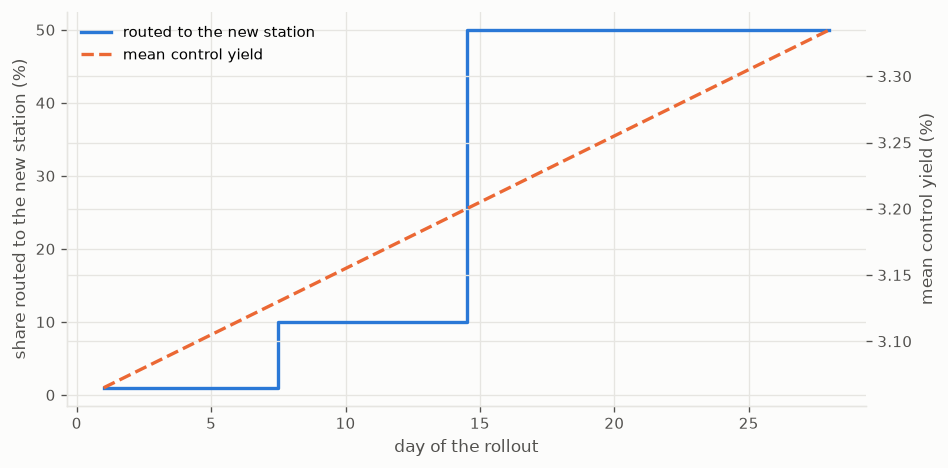

In [6]:
days = np.arange(1, config["days"] + 1)
p = np.zeros(len(days))
for stage in config["schedule"]:
    first, last = stage["days"]
    p[(days >= first) & (days <= last)] = stage["p"]
baseline = config["baseline_yield_rate"] * (1 + config["trend_kappa"] * (days - 14.5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.step(days, 100 * p, where="mid", color=COLOURS[0], label="routed to the new station")
ax.set_xlabel("day of the rollout")
ax.set_ylabel("share routed to the new station (%)")
ax2 = ax.twinx()
ax2.plot(days, 100 * baseline, color=COLOURS[1], linestyle="--", label="mean control yield")
ax2.set_ylabel("mean control yield (%)")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles=handles, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "t1_ramp_timeline.png", metadata={"Software": None})

## Figure T2: three reads of the same rollouts (S1)

Each curve is the distribution of one estimator's relative estimate across the S1 replicates,
drawn from the committed percentiles. The markers show the committed run, which is one draw.

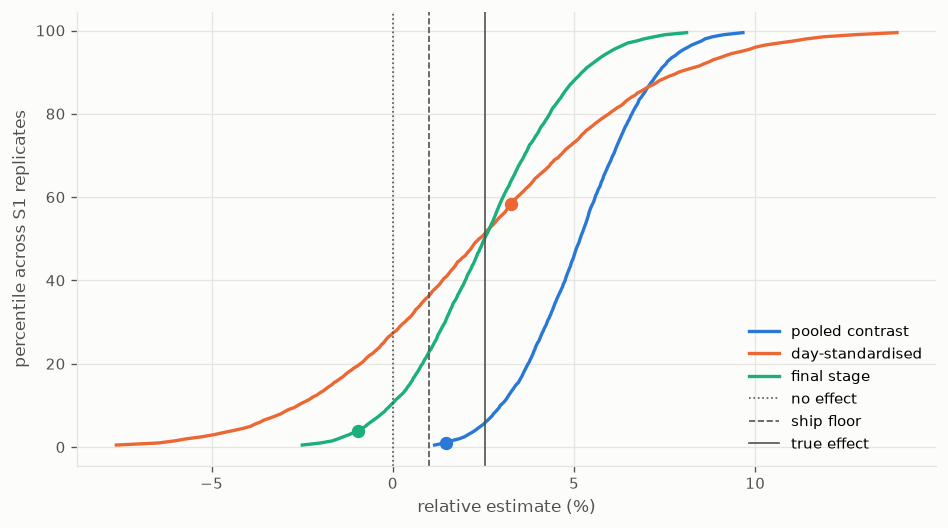

In [7]:
labels = {
    "pooled": "pooled contrast",
    "day_standardised": "day-standardised",
    "final_stage": "final stage",
}
floor = config["decision_rule"]["ship_if_lower_bound_above_relative"]
truth = float(run.loc[run["estimator"] == "pooled", "truth_rel"].iloc[0])

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (name, label) in enumerate(labels.items()):
    part = s1[s1["estimator"] == name].sort_values("percentile")
    x = 100 * part["relative_estimate"].to_numpy()
    y = part["percentile"].to_numpy()
    ax.plot(x, y, color=COLOURS[i], label=label)
    est = 100 * float(run.loc[run["estimator"] == name, "estimate_rel"].iloc[0])
    ax.plot([est], [np.interp(est, x, y)], marker="o", color=COLOURS[i], linestyle="none")
refs = (
    (0.0, ":", "no effect"),
    (100 * floor, "--", "ship floor"),
    (100 * truth, "-", "true effect"),
)
for value, style, name in refs:
    ax.axvline(value, color=PALETTE["ink2"], linestyle=style, linewidth=1, label=name)
ax.set_xlabel("relative estimate (%)")
ax.set_ylabel("percentile across S1 replicates")
ax.legend(loc=4, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "t2_s1_estimates.png", metadata={"Software": None})

## Figure T3: canary power by stage

Exact power of one check at the end of each stage, with the simulated power and two Monte Carlo
standard errors. The dashed line marks 80%.

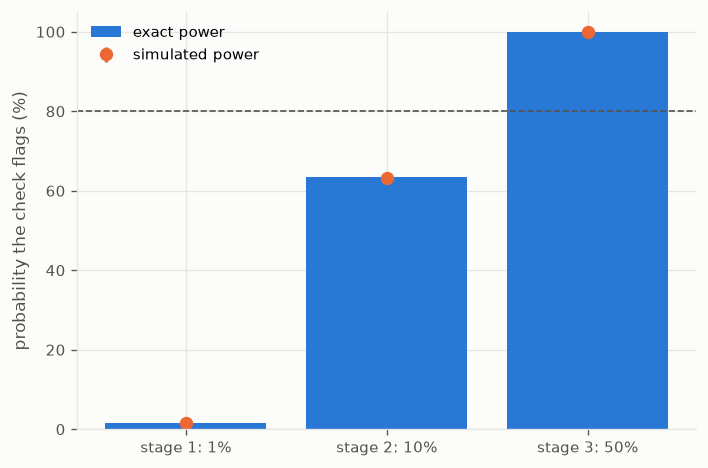

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(canary))
ax.bar(x, 100 * canary["exact_power"], color=COLOURS[0], label="exact power")
ax.errorbar(
    x, 100 * canary["simulated_power"], yerr=200 * canary["mcse"],
    fmt="o", color=COLOURS[1], label="simulated power",
)
ax.axhline(80, color=PALETTE["ink2"], linestyle="--", linewidth=1)
ticks = [f"stage {s}: {100 * r:g}%" for s, r in zip(canary["stage"], canary["routing_p"])]
ax.set_xticks(x, ticks)
ax.set_ylabel("probability the check flags (%)")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "t3_canary_power.png", metadata={"Software": None})